In [2]:
%pip -q install ultralytics kagglehub scikit-learn pillow matplotlib pandas

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import os
import random
import shutil
import hashlib
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageOps, UnidentifiedImageError
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
from ultralytics import YOLO
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
DEVICE = 0 if torch.cuda.is_available() else 'cpu'
print('Device:', DEVICE)
print('Ultralytics YOLO11 classification')

Creating new Ultralytics Settings v0.0.8 file  
View Ultralytics Settings with 'yolo settings' or at 'C:\Users\Alyona\AppData\Roaming\Ultralytics\settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Device: cpu
Ultralytics YOLO11 classification


In [4]:
import kagglehub
root = Path(kagglehub.dataset_download('snmahsa/animal-image-dataset-cats-dogs-and-foxes'))
print('Dataset location:', root)
print('Top-level files:', [p.name for p in root.iterdir()][:25])

c:\Users\Alyona\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 388M/388M [00:18<00:00, 22.5MB/s] 

Extracting files...


Dataset location: C:\Users\Alyona\.cache\kagglehub\datasets\snmahsa\animal-image-dataset-cats-dogs-and-foxes\versions\1
Top-level files: ['Animal Image Dataset-Cats, Dogs, and Foxes']


In [14]:
classes = ['cat', 'dog', 'fox']
aliases = {'cat':'cat','cats':'cat','dog':'dog','dogs':'dog','fox':'fox','foxes':'fox'}
formats = {'.jpg','.jpeg','.png','.webp','.bmp','.jfif'}
unique = {}
conflicts = set()
invalid = unknown = 0

for path in sorted(root.rglob('*')):
    if not path.is_file() or path.suffix.lower() not in formats:
        continue
    label = next((aliases[x.lower()] for x in reversed(path.relative_to(root).parts[:-1])
                  if x.lower() in aliases), None)
    if label is None:
        unknown += 1
        continue
    try:
        with Image.open(path) as im:
            rgb = ImageOps.exif_transpose(im).convert('RGB')
            digest = hashlib.sha256(str(rgb.size).encode()+rgb.tobytes()).hexdigest()
    except (OSError, ValueError, UnidentifiedImageError):
        invalid += 1
        continue
    if digest in unique and unique[digest][1] != label:
        conflicts.add(digest)
    unique.setdefault(digest, (path, label))

records = [r for d, r in unique.items() if d not in conflicts]
counts = Counter(label for _, label in records)

print('Images by class:', dict(counts))

Images by class: {'cat': 100, 'dog': 105, 'fox': 102}


In [15]:
train_records, temp_records = train_test_split(
    records, test_size=0.30, stratify=[label for _,label in records], random_state=SEED)
val_records, test_records = train_test_split(
    temp_records, test_size=0.50, stratify=[label for _,label in temp_records], random_state=SEED)

DATA_DIR = Path.cwd() / 'hw5_animals_yolo'
for split, subset in [('train', train_records), ('val', val_records), ('test', test_records)]:
    for cls in classes:
        target = DATA_DIR / split / cls
        target.mkdir(parents=True, exist_ok=True)
        for old_file in target.iterdir():
            if old_file.is_file(): old_file.unlink()
    for path, label in subset:
        filename = hashlib.sha256(str(path.resolve()).encode()).hexdigest()[:20] + '.jpg'
        with Image.open(path) as im:
            im = ImageOps.exif_transpose(im).convert('RGB')
            im.save(DATA_DIR / split / label / filename, quality=92)
    print(split, len(subset), dict(Counter(y for _, y in subset)))
print('YOLO dataset ready:', DATA_DIR)

train 214 {'fox': 71, 'dog': 73, 'cat': 70}
val 46 {'cat': 15, 'dog': 16, 'fox': 15}
test 47 {'fox': 16, 'dog': 16, 'cat': 15}
YOLO dataset ready: c:\Users\Alyona\Desktop\CV Hws\hw5-transfer-learning\hw5_animals_yolo


In [16]:
model = YOLO('yolo11n-cls.pt')
model.info()

YOLO11n-cls summary: 86 layers, 2,812,104 parameters, 0 gradients, 3.3 GFLOPs


(86, 2812104, 0, 3.31530496)

In [17]:
RUN_DIR = Path.cwd() / 'hw5_yolo_runs'
train_results = model.train(
    data=str(DATA_DIR),
    epochs=10,
    imgsz=224,
    batch=16,
    device=DEVICE,
    workers=0,
    seed=SEED,
    project=str(RUN_DIR),
    name='animals_cls',
    exist_ok=True,
    plots=True,
)
BEST = RUN_DIR / 'animals_cls' / 'weights' / 'best.pt'
assert BEST.is_file(), f'Не найден файл весов: {BEST}'

Ultralytics 8.4.216  Python-3.11.9 torch-2.15.0+cpu CPU (Intel Core i7-10750H 2.60GHz)
engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=c:\Users\Alyona\Desktop\CV Hws\hw5-transfer-learning\hw5_animals_yolo, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=10, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=animals_cl

Test images: 47
Test accuracy: 0.8723
              precision    recall  f1-score   support

         cat       0.92      0.80      0.86        15
         dog       0.88      0.94      0.91        16
         fox       0.82      0.88      0.85        16

    accuracy                           0.87        47
   macro avg       0.88      0.87      0.87        47
weighted avg       0.88      0.87      0.87        47



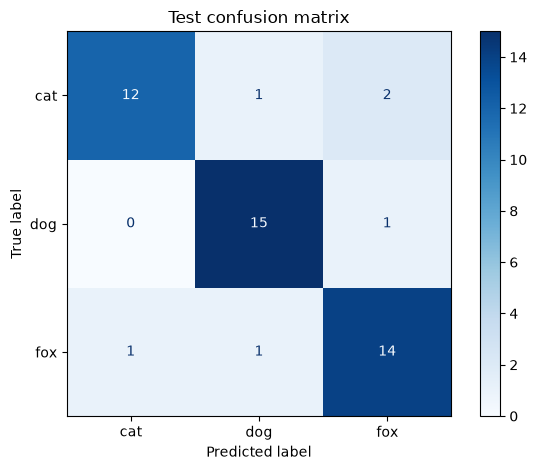

In [18]:
best_model = YOLO(str(BEST))
paths, true_labels = [], []
for label in classes:
    for path in sorted((DATA_DIR / 'test' / label).glob('*.jpg')):
        paths.append(path)
        true_labels.append(label)

pred_labels = []
confidences = []
for path in paths:
    result = best_model.predict(source=str(path), imgsz=224, verbose=False, device=DEVICE)[0]
    index = int(result.probs.top1)
    pred_labels.append(result.names[index])
    confidences.append(float(result.probs.top1conf))

print(f'Test images: {len(paths)}')
print(f'Test accuracy: {accuracy_score(true_labels, pred_labels):.4f}')
print(classification_report(true_labels, pred_labels, labels=classes, zero_division=0))
ConfusionMatrixDisplay.from_predictions(true_labels, pred_labels,
    labels=classes, cmap='Blues', values_format='d')
plt.title('Test confusion matrix'); plt.tight_layout(); plt.show()

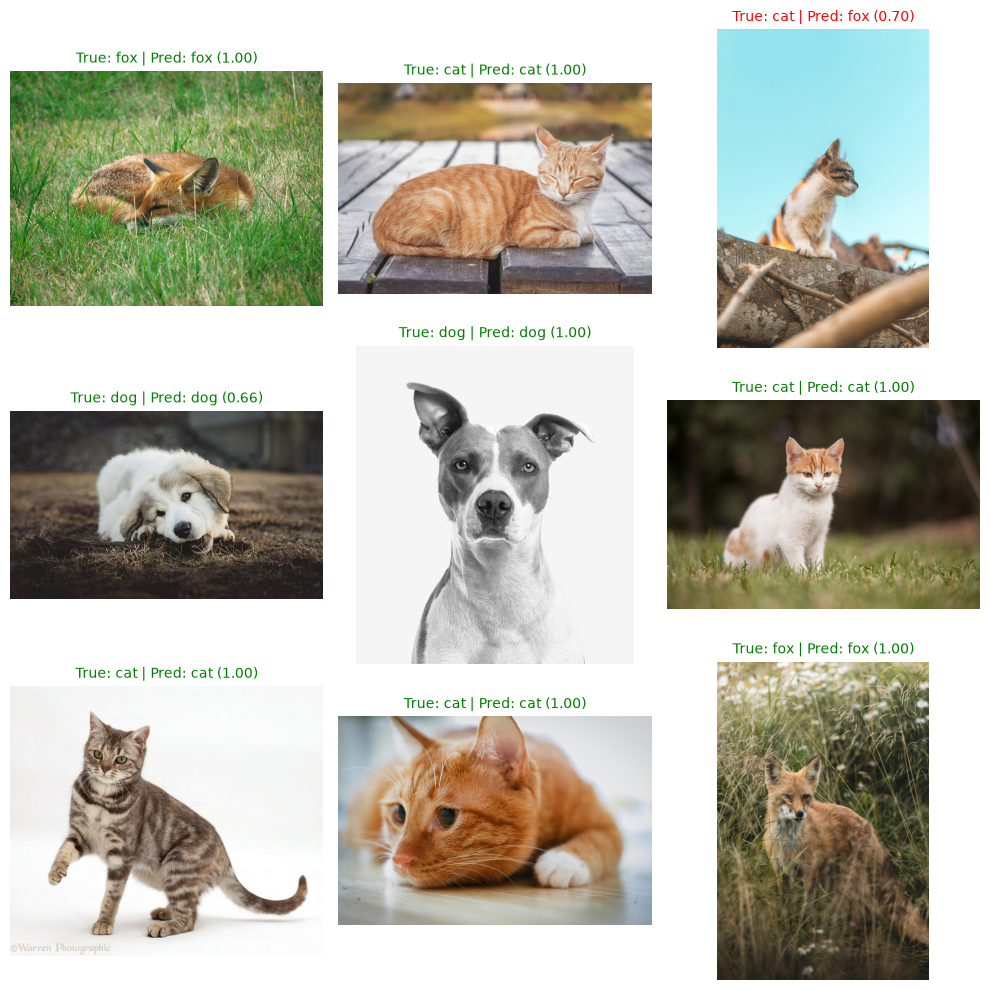

In [19]:
selected = random.Random(SEED).sample(range(len(paths)), min(9, len(paths)))
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for ax in axes.flat: ax.axis('off')
for ax, i in zip(axes.flat, selected):
    with Image.open(paths[i]) as im: ax.imshow(im)
    right = (true_labels[i] == pred_labels[i])
    ax.set_title(f'True: {true_labels[i]} | Pred: {pred_labels[i]} ({confidences[i]:.2f})',
                 fontsize=10, color=('green' if right else 'red'))
plt.tight_layout(); plt.show()

In [20]:
OUTPUT = Path.cwd() / 'hw5_yolo11n_cls_best.pt'
shutil.copy2(BEST, OUTPUT)
print('Test accuracy:', round(accuracy_score(true_labels, pred_labels), 4))

Test accuracy: 0.8723
